# Error Analysis

## Objective

The objective of this notebook is to understand the types of errors made
by the selected Linear SVM model.

We will generate out-of-fold predictions using stratified 5-fold
cross-validation on the training dataset.

Each review will be predicted by a model that was not trained on that
review. This allows us to investigate misclassified examples without
using the held-out test dataset.

The selected model uses:
- TF-IDF with unigrams and bigrams
- min_df = 2
- max_df = 0.95
- sublinear_tf = True
- LinearSVC classifier

We will examine classification metrics, the confusion matrix,
misclassified reviews, and error patterns across product categories
and ratings.

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

In [41]:
train_df = pd.read_csv("../data/processed/train.csv")

X_train = train_df["text"].astype(str)
y_train = train_df["target"].astype(int)

print("Training samples:", len(X_train))
print("Label distribution:")
print(y_train.value_counts())

Training samples: 32328
Label distribution:
target
0    16172
1    16156
Name: count, dtype: int64


In [42]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

In [43]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_predictions = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

print("Out-of-fold predictions generated successfully.")
print("Number of predictions:", len(oof_predictions))

Out-of-fold predictions generated successfully.
Number of predictions: 32328


In [44]:
error_df = pd.DataFrame({
    "text": X_train.values,
    "actual": y_train.values,
    "predicted": oof_predictions
})

error_df["correct"] = (
    error_df["actual"] == error_df["predicted"]
)

total_errors = (~error_df["correct"]).sum()
error_rate = total_errors / len(error_df)

print("Total reviews:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", total_errors)
print(f"Error rate: {error_rate:.4%}")
print(f"Accuracy: {1 - error_rate:.4%}")

Total reviews: 32328
Correct predictions: 30586
Incorrect predictions: 1742
Error rate: 5.3885%
Accuracy: 94.6115%


In [45]:
print("Accuracy:", accuracy_score(y_train, oof_predictions))

print(
    "Macro F1:",
    f1_score(y_train, oof_predictions, average="macro")
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_train, oof_predictions)
)

print("\nClassification Report:\n")

print(classification_report(
    y_train,
    oof_predictions,
    target_names=["OR (Authentic)", "CG (Computer Generated)"],
    digits=4
))

Accuracy: 0.9461148230635981
Macro F1: 0.9461106641314347
Balanced Accuracy: 0.9461107069049804

Classification Report:

                         precision    recall  f1-score   support

         OR (Authentic)     0.9389    0.9544    0.9466     16172
CG (Computer Generated)     0.9536    0.9378    0.9456     16156

               accuracy                         0.9461     32328
              macro avg     0.9462    0.9461    0.9461     32328
           weighted avg     0.9462    0.9461    0.9461     32328



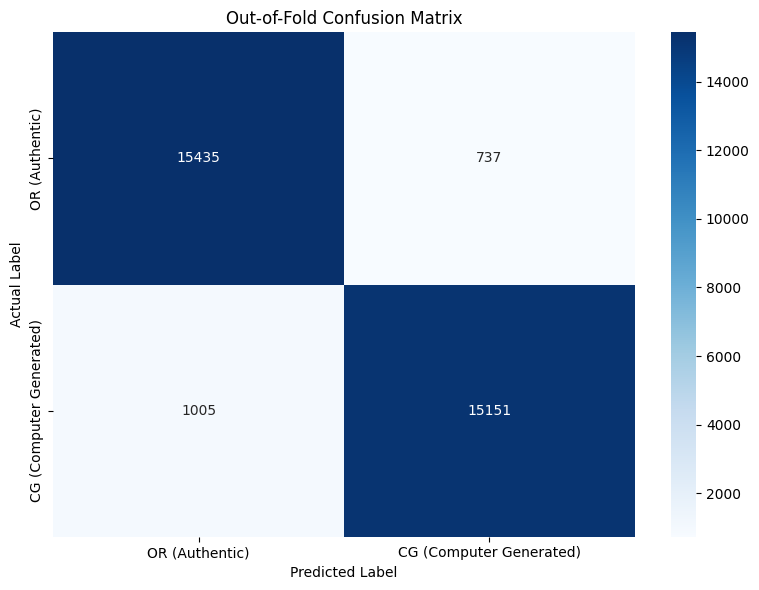

In [46]:
cm = confusion_matrix(y_train, oof_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["OR (Authentic)", "CG (Computer Generated)"],
    yticklabels=["OR (Authentic)", "CG (Computer Generated)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Out-of-Fold Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/oof_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
# Recreate misclassified reviews after metadata has been added
misclassified = error_df[
    ~error_df["correct"]
].copy()

misclassified.to_csv(
    "../results/predictions/oof_misclassified_reviews.csv",
    index=False
)

print("Misclassified reviews saved successfully.")
print("Number of saved reviews:", len(misclassified))
print("Columns:", misclassified.columns.tolist())

Misclassified reviews saved successfully.
Number of saved reviews: 1742
Columns: ['text', 'actual', 'predicted', 'correct', 'category', 'rating']


In [48]:
pd.set_option("display.max_colwidth", None)

print("OR incorrectly classified as CG:")

display(
    or_misclassified_as_cg[
        ["text", "actual", "predicted"]
    ].head(5)
)

print("\nCG incorrectly classified as OR:")

display(
    cg_misclassified_as_or[
        ["text", "actual", "predicted"]
    ].head(5)
)

OR incorrectly classified as CG:


,text,actual,predicted
53,"The chemistry between Chase and Violet is undeniably refreshing. Chase is a military man with a toddler daughter, and a widower. Chase's daughter has his heart, and then his deceased wife's childhood friend arrives to see the wife, and claims his and baby Ava's heart. Chase is not sure if he can forget the past and embrace the future. Violet is a trust fund heiress, who is loving , kind , compassionate, and very generous. Upon setting her eyes on Chase, she knows Chase and Ava has stolen her heart. Will Chase forget old hurts and embrace the love he has never had with anyone else? The storyline is great, just too short. How will the flyboy and the heiress meet in the middle to embark on a grand adventure to love?",0,1
68,Nice leash with comfortable handle. The leash itself is a little more lightweight than I would've liked but my dog is not really a puller so it will be fine.,0,1
81,"I love to make custard in the cold months, and this is a nice matched set that work very well.",0,1
126,"Liquid K9 Glucosamine has been a lifesaver for my St. Bernard mix. She has hip dysplasia, and has been taking this since she was four years old. It is easy to use- I just pour it on her food. It has kept her on her feet for the last seven years.",0,1
207,"loved the scissors style tool, the tweezers and the bulb syringe. The yellow tool (pictured on the left hand side) was pretty cool, BUT it broke the first day of use. The quality of that tool was not as good as the other three.",0,1



CG incorrectly classified as OR:


,text,actual,predicted
7,"LOVE, LOVE, LOVE THEM, LOVE MY GIRL!!!\n\nI have a large",1,0
29,I have narrow feet and this shoe is perfect. I will definitely be buying this shoe again.,1,0
33,"Terrible, complete waste of money. Not a whole lot to say.",1,0
38,Excellent\nThis review requires that I go back and read the earlier reviews. This review is based,1,0
47,"Purchased for my for her (i.e., her husband) and she loves it!",1,0


In [49]:
# Load the original dataset
raw_df = pd.read_csv("../data/raw/fake reviews dataset.csv")

# Apply the same cleaning and duplicate removal as Notebook 2
raw_df["text_"] = raw_df["text_"].str.strip()

raw_df = raw_df.drop_duplicates(
    subset=["text_"],
    keep="first"
).reset_index(drop=True)

# Extract metadata
metadata_df = raw_df[
    ["text_", "category", "rating"]
].copy()

# Match metadata with the training reviews
error_df = error_df.merge(
    metadata_df,
    left_on="text",
    right_on="text_",
    how="left",
    validate="one_to_one"
)

# Remove the redundant text column
error_df.drop(columns=["text_"], inplace=True)

# Verify the merge
print("Missing categories:", error_df["category"].isna().sum())
print("Missing ratings:", error_df["rating"].isna().sum())

print("\nUpdated error analysis dataset:")
display(error_df.head())

Missing categories: 0
Missing ratings: 0

Updated error analysis dataset:


,text,actual,predicted,correct,category,rating
0,"I absolutely love this print/design! I love the look and feel of this print, the color and the appearance. I've used it on my son's bed, on a bedding frame, and on his bed in the living room. I love it! I would definitely buy again. I have a few more things I'd like to add to the collection!I use this to make homemade coffee and it is great! It's easy to clean and easy to clean! I would highly recommend it.I bought these for my daughter to use for her baked goods",1,1,True,Home_and_Kitchen_5,5.0
1,"Something is very wrong here.\n\nI suppose there were aspects of this movie that were not deemed politically correct.\n\nThe movie never saw the theatre circuit, so I read. Shame, really.\n\nVal Kilmer deserved an Academy Award for his performance. But, then, that would be kind of difficult to explain. Would it not?\n\nThis movie is a Must See.\n\nDon't know what else to say without being cliche.",0,0,True,Movies_and_TV_5,5.0
2,"All Megabomber stories are written by people with very different personalities. This is a great book. I read this book in the middle of the night, and it was great. The story was well told, and the characters were well developed. This is a great series for adults and teens. I highly recommend it. I had to wait a year for this book to get published. This book is a must read for any young adult.",1,1,True,Books_5,2.0
3,We use these in our Data Center and found these are a great price and you cannot go wrong with Leviton.,0,0,True,Tools_and_Home_Improvement_5,5.0
4,"Just a tad large, but the straps are adjustable. Very comfortable bra, can wear all day without wanting to rip it off!",0,0,True,Clothing_Shoes_and_Jewelry_5,5.0


In [50]:
category_summary = (
    error_df.groupby("category")
    .agg(
        total_reviews=("correct", "size"),
        incorrect_predictions=(
            "correct",
            lambda x: (~x).sum()
        ),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

category_summary["error_rate"] = (
    1 - category_summary["accuracy"]
)

category_summary = category_summary.sort_values(
    "error_rate",
    ascending=False
)

category_summary

,category,total_reviews,incorrect_predictions,accuracy,error_rate
5,Movies_and_TV_5,2901,198,0.931748,0.068252
0,Books_5,3494,233,0.933314,0.066686
1,Clothing_Shoes_and_Jewelry_5,3025,173,0.942810,0.057190
4,Kindle_Store_5,3736,199,0.946734,0.053266
6,Pet_Supplies_5,3359,176,0.947603,0.052397
7,Sports_and_Outdoors_5,3164,163,0.948483,0.051517
9,Toys_and_Games_5,3021,155,0.948692,0.051308
8,Tools_and_Home_Improvement_5,3147,153,0.951382,0.048618
3,Home_and_Kitchen_5,3261,150,0.954002,0.045998
2,Electronics_5,3220,142,0.955901,0.044099


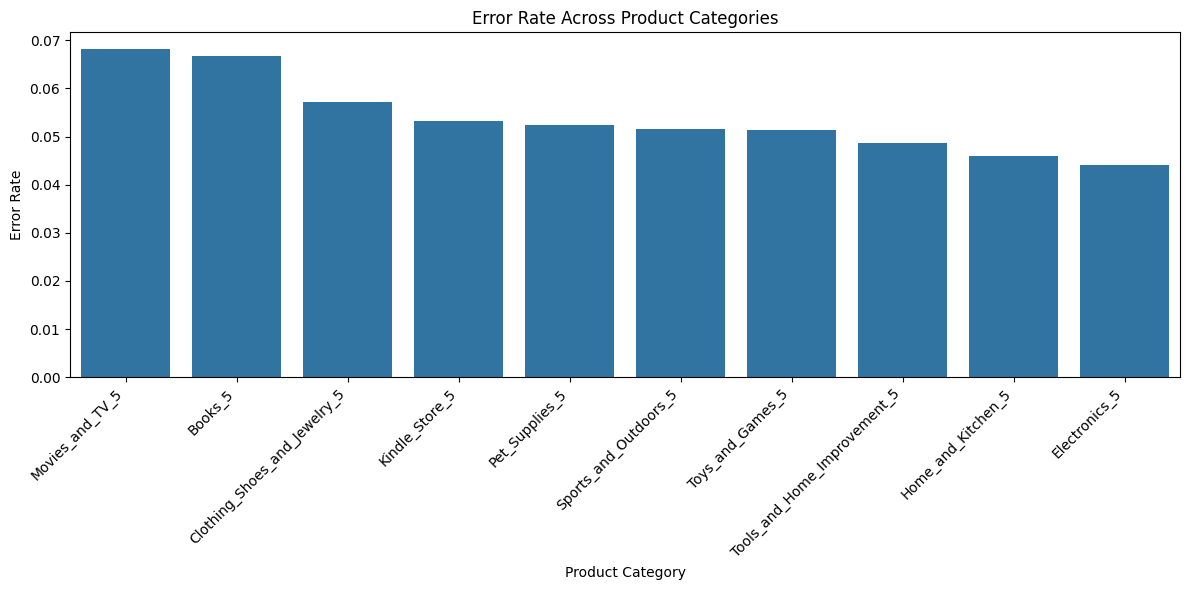

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_summary,
    x="category",
    y="error_rate"
)

plt.title("Error Rate Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Error Rate")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "../results/figures/category_error_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
rating_summary = (
    error_df.groupby("rating")
    .agg(
        total_reviews=("correct", "size"),
        incorrect_predictions=(
            "correct",
            lambda x: (~x).sum()
        ),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

rating_summary["error_rate"] = (
    1 - rating_summary["accuracy"]
)

rating_summary

,rating,total_reviews,incorrect_predictions,accuracy,error_rate
0,1.0,1724,72,0.958237,0.041763
1,2.0,1556,67,0.956941,0.043059
2,3.0,3022,136,0.954997,0.045003
3,4.0,6386,312,0.951143,0.048857
4,5.0,19640,1155,0.941191,0.058809


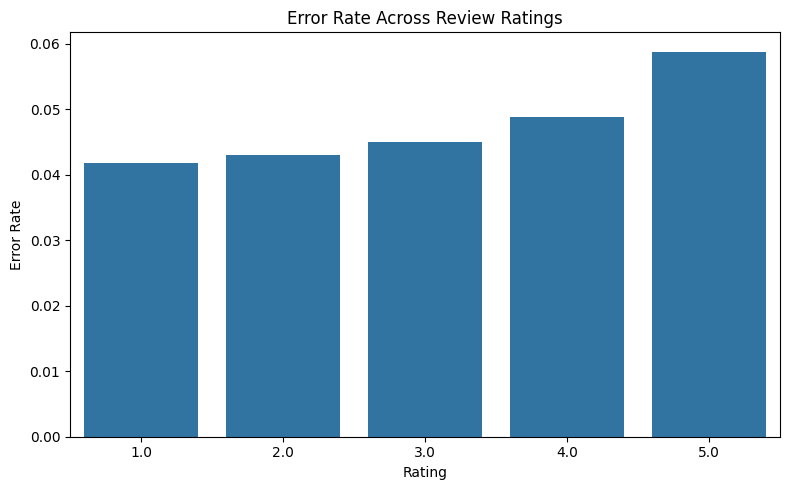

In [53]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=rating_summary,
    x="rating",
    y="error_rate"
)

plt.title("Error Rate Across Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Error Rate")

plt.tight_layout()

plt.savefig(
    "../results/figures/rating_error_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
misclassified.to_csv(
    "../results/predictions/oof_misclassified_reviews.csv",
    index=False
)

print("Misclassified reviews saved successfully.")

Misclassified reviews saved successfully.


## Conclusion

The error analysis shows that the LinearSVC model with TF-IDF and sublinear term frequency achieved an out-of-fold accuracy of approximately 94.61% and a macro F1-score of 0.9461 on the training dataset.

The confusion matrix indicates that the model misclassified more computer-generated (CG) reviews as original (OR) reviews (1,005) than original reviews as computer-generated (737). This suggests that identifying CG reviews is slightly more challenging for the model.

The category-level analysis shows variation in error rates across product categories. Movies & TV and Books had the highest error rates, while Electronics and Home & Kitchen had the lowest.

The rating-level analysis shows that error rates generally increased with rating, from 4.18% for one-star reviews to 5.88% for five-star reviews.

These findings suggest that model performance varies across different types of reviews. However, the observed patterns are associations within this dataset and do not establish the reasons behind the errors.

Overall, the error analysis helps identify where the model struggles and provides useful context for interpreting its performance.